# PETE 662 Project 2 — Notebook 01: Validation and First Nodal Analysis
**Carlos Buenrostro**

The calculation code now lives in the `pete662_nodal` package (the `.py` files next to this notebook).
This notebook imports it, so **edit the `.py` files, save, and re-run a cell** — `autoreload` picks up the change
without restarting the kernel.

| Module | Contents |
|---|---|
| `inputs.py` | `WellboreCase` — depth, ptf, tubing, GOR/WOR, fluid (same names as your HW5 globals) |
| `pvt.py` | `AppendixBPVT` — Appendix-B curve PVT from HW5 (to be replaced by correlations) |
| `ipr.py` | `IPRInputs`, `ReservoirInputs` (radial PI with skin), PI / Vogel / generalized Vogel |
| `hagedorn_brown.py` | Modified H-B + Griffith bubble flow (**Griffith friction corrected**, Eqs. 7-111–7-116) |
| `beggs_brill.py` | Beggs-Brill + Payne |
| `traverse.py` | `pressure_traverse`, `vlp_curve` |
| `nodal.py` | `operating_point` (stable IPR/VLP crossing), `run_sensitivity` |

In [2]:
%load_ext autoreload
%autoreload 2

from dataclasses import replace
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pete662_nodal import (WellboreCase, IPRInputs, ReservoirInputs, oil_rate, ipr_table,
                           pressure_traverse, vlp_curve, operating_point, run_sensitivity)
from pete662_nodal.hagedorn_brown import hb_dimensionless_groups, hb_holdup_from_groups
from pete662_nodal.beggs_brill import bb_flow_regime, bb_holdup

## 1. Automated tests
Runs every check in `tests/` (Examples 7-8 and 7-9, HW5/Exam 1 regression, IPR, nodal solver). All should pass.

In [4]:
!python -m pytest -q

..........................................                               [100%]
42 passed in 3.47s


## 2. Textbook Example 7-8 — modified Hagedorn-Brown

In [6]:
D = 2.259 / 12
NvL, Nvg, ND, NL = hb_dimensionless_groups(usL=4.67, usg=8.72, rhoL=49.9, muL=2.0, sigma_L=30.0, D=D)
HL, det = hb_holdup_from_groups(NvL, Nvg, ND, NL, p=800.0)

pd.DataFrame({
    "Python":   [NvL, Nvg, ND, NL, det["CNL"], det["psi"], HL],
    "Textbook": [10.28, 19.20, 29.35, 0.00926, 0.0022, 1.0, 0.46],
}, index=["N_vL", "N_vg", "N_D", "N_L", "C_NL", "psi", "H_L"]).round(5)

,Python,Textbook
N_vL,10.27816,10.28000
N_vg,19.19177,19.20000
N_D,29.34610,29.35000
N_L,0.00923,0.00926
C_NL,0.00235,0.00220
psi,1.06157,1.00000
H_L,0.50839,0.46000


*H_L differs (0.508 vs 0.46) because the code evaluates Eqs. 7-103–7-107 directly, while the worked example uses
chart readings. Reported, not tuned — see the VER1 notebook.*

## 3. Textbook Example 7-9 — Beggs-Brill + Payne

In [8]:
lam, um = 0.35, 13.39
NFR = um**2 / (32.174 * D)
HL, det = bb_holdup(lam, NFR, NvL=10.28, theta_deg=90)

pd.DataFrame({
    "Python":   [NFR, det["HL0"], det["C"], det["psi"], det["HL_original"], HL],
    "Textbook": [29.6, 0.454, 0.0351, 1.01, 0.459, 0.424],
}, index=["N_FR", "H_L(0)", "C", "psi", "H_L original", "H_L Payne"]).round(4)

,Python,Textbook
N_FR,29.6020,29.6000
H_L(0),0.4544,0.4540
C,0.0351,0.0351
psi,1.0105,1.0100
H_L original,0.4592,0.4590
H_L Payne,0.4243,0.4240


## 4. Exam 1 Problem 1 case — inputs
Same values as `BUENROSTRO-Exam1-Prep-Problem1-VLP-IPR-Executed.ipynb`.

In [10]:
well = WellboreCase(
    depth=9000.0, ptf=100.0, T_surface=150.0, T_bottom=180.0, dz=200.0,
    D_in=2.44, rel_roughness=0.0006,
    GOR=750.0, WOR=0.0,
    API=32.0, gamma_g=0.71, pb=4336.0, Rsb=800.0, sigma_L=30.0, mu_g=0.015,
)

reservoir = ReservoirInputs(
    reservoir_pressure=3000.0, bubblepoint_pressure=4336.0,
    k_md=13.0, kro=0.5, h_ft=115.0, mu_o_cp=0.5, Bo=1.46,
    re_ft=1490.0, rw_ft=0.25, skin=0.0, pseudo_steady=True,
)
ipr = reservoir.to_ipr()
print(f"J = {reservoir.J:.3f} STB/d/psi,   q_max = {oil_rate(0, ipr):.1f} STB/d")

J = 0.913 STB/d/psi,   q_max = 1521.2 STB/d


## 5. One pressure traverse

In [12]:
pwf, profile = pressure_traverse(1200, well, "HB", return_profile=True)
print(f"q = 1200 STB/d  ->  pwf = {pwf:.1f} psia")
print(profile["Regime"].value_counts().to_dict())
profile.round(3).head(10)

q = 1200 STB/d  ->  pwf = 1446.9 psia
{'Hagedorn-Brown': 45}


,Depth ft,P_in psia,P_avg psia,T_avg F,dp/dz psi/ft,dP psi,P_out psia,HL,Regime,Iterations
0,200.0,100.000,109.167,150.333,0.092,18.326,118.326,0.209,Hagedorn-Brown,14
1,400.0,118.326,127.798,151.000,0.095,18.938,137.263,0.220,Hagedorn-Brown,14
2,600.0,137.263,147.052,151.667,0.098,19.571,156.834,0.231,Hagedorn-Brown,14
3,800.0,156.834,166.940,152.333,0.101,20.205,177.039,0.242,Hagedorn-Brown,14
4,1000.0,177.039,187.459,153.000,0.104,20.832,197.872,0.253,Hagedorn-Brown,14
5,1200.0,197.872,208.599,153.667,0.107,21.449,219.320,0.263,Hagedorn-Brown,14
6,1400.0,219.320,230.350,154.333,0.110,22.052,241.372,0.273,Hagedorn-Brown,14
7,1600.0,241.372,252.697,155.000,0.113,22.643,264.016,0.283,Hagedorn-Brown,14
8,1800.0,264.016,275.630,155.667,0.116,23.222,287.237,0.292,Hagedorn-Brown,14
9,2000.0,287.237,299.134,156.333,0.119,23.788,311.026,0.301,Hagedorn-Brown,14


## 6. Operating point (IPR / VLP intersection)

NodalResult(flowing: q = 1110.5 STB/d, pwf = 1407.8 psia)


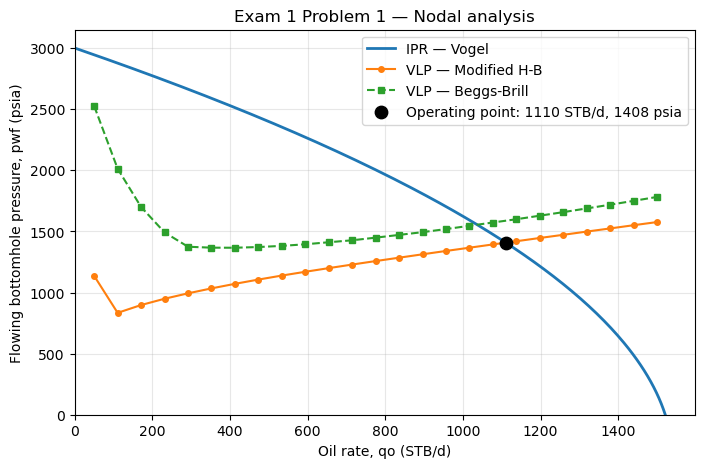

In [14]:
result = operating_point(reservoir, well, method="HB")
print(result)
if result.unstable_points:
    print("Unstable (loading-branch) crossings:", result.unstable_points)

ipr_df = ipr_table(ipr, 200)
vlp_hb = vlp_curve(np.linspace(50, 1500, 25), well, "HB")
vlp_bb = vlp_curve(np.linspace(50, 1500, 25), well, "BB")

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(ipr_df.qo_stb_day, ipr_df.pwf_psia, lw=2, label="IPR — Vogel")
ax.plot(vlp_hb["qo (STB/d)"], vlp_hb["VLP pwf (psia)"], "o-", ms=4, label="VLP — Modified H-B")
ax.plot(vlp_bb["qo (STB/d)"], vlp_bb["VLP pwf (psia)"], "s--", ms=4, label="VLP — Beggs-Brill")
if result.status == "flowing":
    ax.scatter([result.q], [result.pwf], s=80, zorder=5, color="k",
               label=f"Operating point: {result.q:.0f} STB/d, {result.pwf:.0f} psia")
ax.set(xlabel="Oil rate, qo (STB/d)", ylabel="Flowing bottomhole pressure, pwf (psia)",
       title="Exam 1 Problem 1 — Nodal analysis", xlim=(0, None), ylim=(0, None))
ax.grid(alpha=0.3); ax.legend(); plt.show()

## 7. Sensitivity studies
`run_sensitivity` varies **one** input and holds the rest. Any `WellboreCase` field (`D_in`, `ptf`, `GOR`, `WOR`, …)
or `ReservoirInputs` field (`skin`, `k_md`, `reservoir_pressure`, …) can be used.

,D_in,status,q (STB/d),pwf (psia),J (STB/d/psi)
0,2.00,flowing,955.11,1705.22,0.91
1,2.44,flowing,1110.48,1407.77,0.91
2,2.99,flowing,1222.05,1159.01,0.91


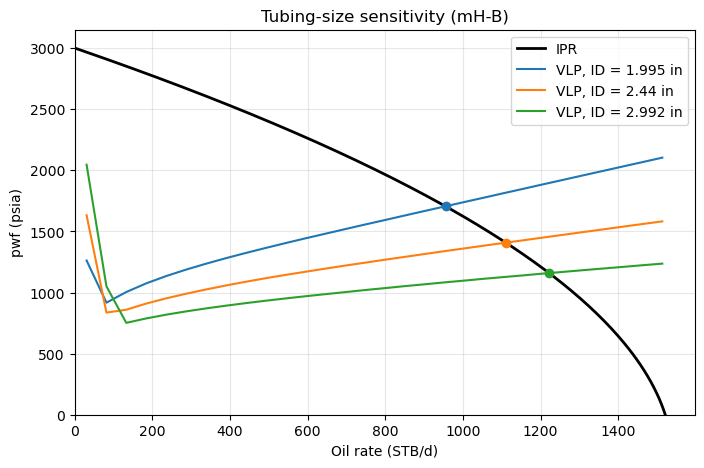

In [16]:
summary, runs = run_sensitivity(reservoir, well, "D_in", [1.995, 2.44, 2.992])
display(summary.round(2))

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(ipr_df.qo_stb_day, ipr_df.pwf_psia, "k", lw=2, label="IPR")
for d_in, r in zip(summary["D_in"], runs):
    t = r.table
    line, = ax.plot(t["qo (STB/d)"], t["VLP pwf (psia)"], label=f"VLP, ID = {d_in} in")
    if r.status == "flowing":
        ax.scatter([r.q], [r.pwf], color=line.get_color(), zorder=5)
ax.set(xlabel="Oil rate (STB/d)", ylabel="pwf (psia)", title="Tubing-size sensitivity (mH-B)",
       xlim=(0, None), ylim=(0, None))
ax.grid(alpha=0.3); ax.legend(); plt.show()

,skin,status,q (STB/d),pwf (psia),J (STB/d/psi)
0,0,flowing,1110.48,1407.77,0.91
1,5,flowing,729.92,1235.76,0.56
2,10,flowing,543.65,1144.35,0.40
3,20,flowing,360.95,1039.14,0.26


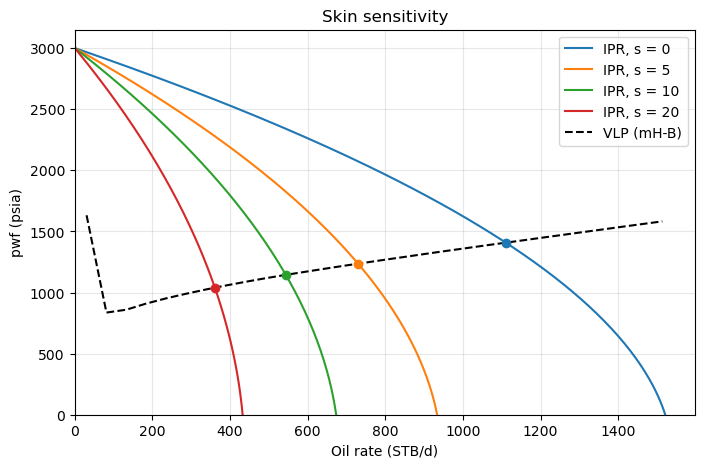

In [17]:
summary, runs = run_sensitivity(reservoir, well, "skin", [0, 5, 10, 20])
display(summary.round(2))

fig, ax = plt.subplots(figsize=(8, 5))
for s, r in zip(summary["skin"], runs):
    df = ipr_table(replace(reservoir, skin=s).to_ipr(), 150)
    line, = ax.plot(df.qo_stb_day, df.pwf_psia, label=f"IPR, s = {s}")
    if r.status == "flowing":
        ax.scatter([r.q], [r.pwf], color=line.get_color(), zorder=5)
ax.plot(runs[0].table["qo (STB/d)"], runs[0].table["VLP pwf (psia)"], "k--", label="VLP (mH-B)")
ax.set(xlabel="Oil rate (STB/d)", ylabel="pwf (psia)", title="Skin sensitivity",
       xlim=(0, None), ylim=(0, None))
ax.grid(alpha=0.3); ax.legend(); plt.show()

## Next steps
1. **PVT correlations** in `pvt.py` (Standing Rs/Bo, oil viscosity, smooth Z-factor) — `AppendixBPVT` stays for regression checks.
2. Optional: switch `friction_method="chen"` (book Eq. 7-35) once correlations are in.
3. `app.py` — Streamlit front end that calls `operating_point` and `run_sensitivity`.